## 1. Imports

In [1]:
import ast
import gc
import os
import platform
import re
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MaxNLocator, NullFormatter
from matplotlib.patches import FancyBboxPatch
import imblearn
import sklearn
import xgboost
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, confusion_matrix, fbeta_score,
    matthews_corrcoef, precision_recall_curve, precision_score, recall_score,
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import RobustScaler
from xgboost import XGBClassifier

## 2. Configuração e auxiliares de figuras

In [2]:
RANDOM_STATE = 42
CSV_PATH = "../data/creditcard.csv"
RESULTS = "../results/"
LARG = 6.3                     

assert any("Times New Roman" in f.name for f in font_manager.fontManager.ttflist), \
    "Times New Roman não encontrada no sistema"
sns.set_theme(style="whitegrid", font="Times New Roman")
plt.rcParams.update({
    "font.size": 10, "axes.labelsize": 10, "axes.titlesize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "axes.unicode_minus": False, "figure.dpi": 120,
})

COR = {"LR": "#1f77b4", "NB": "#7f7f7f", "RF": "#2ca02c", "XGB": "#d62728"}
MARC = {"LR": "o", "NB": "s", "RF": "^", "XGB": "D"}
NOMES = {"LR+peso": "RL (peso)", "LR+smote": "RL (SMOTE)", "NB+none": "NB", "NB+smote": "NB (SMOTE)",
         "RF+peso": "RF (peso)", "RF+smote": "RF (SMOTE)", "XGB+peso": "XGB (peso)", "XGB+smote": "XGB (SMOTE)"}
fam = lambda cfg: cfg.split("+")[0]
cor = lambda cfg: COR[fam(cfg)]
marc = lambda cfg: MARC[fam(cfg)]

def num(v, casas=None):
    """Número no padrão brasileiro: vírgula decimal e ponto de milhar."""
    s = f"{v:,.{casas}f}" if casas is not None else f"{v:,.10g}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")

def ptbr(ax, x=True, y=True):
    f = FuncFormatter(lambda v, _: num(v))
    if x: ax.xaxis.set_major_formatter(f)
    if y: ax.yaxis.set_major_formatter(f)

def salvar(fig, nome):
    fig.savefig(RESULTS + nome, dpi=300, bbox_inches="tight")
    plt.show()

## 3. Carga dos dados e split temporal

In [3]:
def load_data(csv_path: str) -> pd.DataFrame:
    df = pd.read_csv(csv_path)
    assert {"Time", "Class"} <= set(df.columns), "Colunas Time/Class ausentes"
    n0 = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Duplicatas removidas: {n0 - len(df)}")
    return df

def temporal_split(df: pd.DataFrame, val_frac: float = 0.15, test_frac: float = 0.15):
    """Split temporal em treino/validação/teste, ordenado por 'Time'."""
    df = df.sort_values("Time").reset_index(drop=True)
    n = len(df)
    i_val = int(n * (1 - val_frac - test_frac))
    i_test = int(n * (1 - test_frac))
    train_df = df.iloc[:i_val].copy()
    val_df = df.iloc[i_val:i_test].copy()
    test_df = df.iloc[i_test:].copy()

    for nome, d in [("Treino", train_df), ("Validação", val_df), ("Teste", test_df)]:
        print(f"{nome:<10}: {len(d):>7} transações | Fraudes: {int(d['Class'].sum()):>4} "
              f"({d['Class'].mean()*100:.4f}%)")
    return train_df, val_df, test_df

df = load_data(CSV_PATH)
train_df, val_df, test_df = temporal_split(df)

Duplicatas removidas: 1081
Treino    :  198608 transações | Fraudes:  366 (0.1843%)
Validação :   42559 transações | Fraudes:   55 (0.1292%)
Teste     :   42559 transações | Fraudes:   52 (0.1222%)


## 4. Análise exploratória (EDA)

Transações com Amount = 0 omitidas no painel (c): 1371


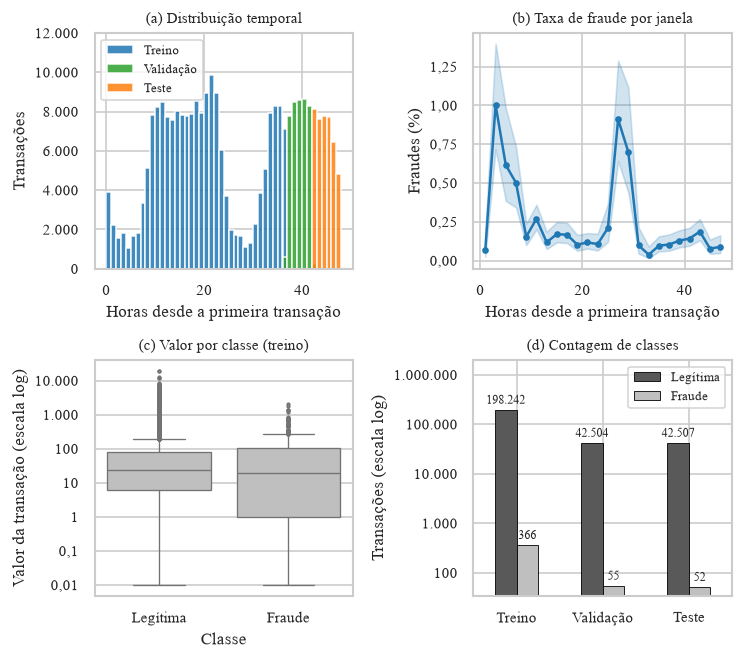

In [4]:
os.makedirs(RESULTS, exist_ok=True)

def wilson_ci(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    margem = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - margem, centro + margem

def plot_eda(train_df, val_df, test_df, n_janelas=24):
    full = pd.concat([train_df, val_df, test_df])
    fig, ax = plt.subplots(2, 2, figsize=(LARG, 5.6))
    cores = {"Treino": "tab:blue", "Validação": "tab:green", "Teste": "tab:orange"}

    # (a) Split temporal (bins comuns, em horas)
    bins = np.linspace(full["Time"].min(), full["Time"].max(), 49) / 3600
    for d, lbl in [(train_df, "Treino"), (val_df, "Validação"), (test_df, "Teste")]:
        ax[0, 0].hist(d["Time"] / 3600, bins=bins, alpha=0.85, label=lbl, color=cores[lbl])
    ax[0, 0].set_title("(a) Distribuição temporal", fontsize=9)
    ax[0, 0].set_xlabel("Horas desde a primeira transação"); ax[0, 0].set_ylabel("Transações")
    ax[0, 0].legend(fontsize=8, loc="upper left"); ptbr(ax[0, 0])
    ax[0, 0].set_ylim(top=12000)          

    # (b) Taxa de fraude por janela, com IC de Wilson
    jan = full.assign(janela=pd.cut(full["Time"], bins=n_janelas))
    g = jan.groupby("janela", observed=True)["Class"].agg(fraudes="sum", n="count")
    lo, hi = wilson_ci(g["fraudes"], g["n"])
    horas = np.array([iv.mid for iv in g.index]) / 3600
    ax[0, 1].plot(horas, g["fraudes"] / g["n"] * 100, marker="o", ms=3, color="tab:blue")
    ax[0, 1].fill_between(horas, lo * 100, hi * 100, alpha=0.2, color="tab:blue")
    ax[0, 1].set_title("(b) Taxa de fraude por janela", fontsize=9)
    ax[0, 1].set_xlabel("Horas desde a primeira transação"); ax[0, 1].set_ylabel("Fraudes (%)")
    ax[0, 1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v)))
    ax[0, 1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v, 2)))  

    # (c) Valor da transação por classe (somente Amount > 0)
    tr = train_df[train_df["Amount"] > 0]
    sns.boxplot(data=tr, x="Class", y="Amount", ax=ax[1, 0], color="0.75", linewidth=0.8, fliersize=1.5)
    ax[1, 0].set_yscale("log"); ax[1, 0].yaxis.set_minor_formatter(NullFormatter())
    ax[1, 0].set_xticks([0, 1]); ax[1, 0].set_xticklabels(["Legítima", "Fraude"])
    ax[1, 0].set_xlabel("Classe")
    ax[1, 0].set_ylabel("Valor da transação (escala log)")
    ax[1, 0].set_title("(c) Valor por classe (treino)", fontsize=9)
    ptbr(ax[1, 0], x=False)
    n_zero = int((train_df["Amount"] == 0).sum())
    print(f"Transações com Amount = 0 omitidas no painel (c): {n_zero}")

    # (d) Contagem de classes por conjunto
    contagem = pd.DataFrame({"Treino": train_df["Class"].value_counts(),
                             "Validação": val_df["Class"].value_counts(),
                             "Teste": test_df["Class"].value_counts()}).T
    contagem = contagem.rename(columns={0: "Legítima", 1: "Fraude"})
    contagem.plot(kind="bar", ax=ax[1, 1], logy=True, color=["0.35", "0.75"], edgecolor="black", linewidth=0.5)
    for cont in ax[1, 1].containers:
        ax[1, 1].bar_label(cont, labels=[num(int(v)) for v in cont.datavalues], fontsize=7, padding=2)
    ax[1, 1].set_ylim(top=2e6); ax[1, 1].tick_params(axis="x", rotation=0)
    ax[1, 1].set_ylabel("Transações (escala log)"); ax[1, 1].set_xlabel("")
    ax[1, 1].set_title("(d) Contagem de classes", fontsize=9)
    ax[1, 1].legend(fontsize=8, loc="upper right"); ptbr(ax[1, 1], x=False)
    ax[1, 1].yaxis.set_minor_formatter(NullFormatter())

    fig.tight_layout()
    salvar(fig, "eda.png")

plot_eda(train_df, val_df, test_df)

## 5. Avaliação principal (sem Time)

In [5]:
FEATURES = [f"V{i}" for i in range(1, 29)] + ["Amount"]   # sem Time
CONFIGS = [("LR", "peso"), ("LR", "smote"),
           ("NB", "none"), ("NB", "smote"),
           ("RF", "peso"), ("RF", "smote"),
           ("XGB", "peso"), ("XGB", "smote")]

def build_pipe(modelo, balanceamento, features, y_tr):
    """Pipeline sem vazamento: escala (só Amount) -> [SMOTE] -> classificador.
    O SMOTE só atua no fit; na predição o imblearn o ignora."""
    peso = balanceamento == "peso"
    spw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
    if modelo == "LR":
        clf = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                                 class_weight="balanced" if peso else None)
    elif modelo == "NB":
        clf = GaussianNB()
    elif modelo == "RF":
        clf = RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=-1,
                                     random_state=RANDOM_STATE,
                                     class_weight="balanced_subsample" if peso else None)
    elif modelo == "XGB":
        clf = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                            subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                            scale_pos_weight=spw if peso else 1.0, eval_metric="aucpr",
                            n_jobs=-1, random_state=RANDOM_STATE)
    pre = ColumnTransformer([("amt", RobustScaler(), ["Amount"])], remainder="passthrough")
    steps = [("pre", pre)]
    if balanceamento == "smote":
        steps.append(("smote", SMOTE(sampling_strategy=0.1, random_state=RANDOM_STATE)))
    steps.append(("clf", clf))
    return ImbPipeline(steps)

def melhor_limiar_f2(y, s):
    """Limiar que maximiza F2 (usar SOMENTE na validação)."""
    p, r, t = precision_recall_curve(y, s)
    f2 = 5 * p[:-1] * r[:-1] / np.clip(4 * p[:-1] + r[:-1], 1e-12, None)
    return t[np.argmax(f2)]

def metricas(y, s, thr):
    pred = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F2": fbeta_score(y, pred, beta=2, zero_division=0),
            "MCC": matthews_corrcoef(y, pred),
            "PR-AUC": average_precision_score(y, s),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

def bootstrap_ic(y, s, thr, n_boot=500):
    """IC 95% (percentil) de PR-AUC, F2 e MCC no teste, com limiar fixo."""
    rng = np.random.default_rng(RANDOM_STATE)
    y, s = np.asarray(y), np.asarray(s)
    vals = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0:
            continue
        m = metricas(y[i], s[i], thr)
        vals.append((m["PR-AUC"], m["F2"], m["MCC"]))
    lo, hi = np.percentile(np.array(vals), [2.5, 97.5], axis=0)
    return dict(zip(["PR-AUC", "F2", "MCC"], zip(lo, hi)))

def avaliar(train, val, test, features, configs, rotulo="principal", n_boot=500):
    Xtr, ytr = train[features], train["Class"].values
    Xva, yva = val[features], val["Class"].values
    Xte, yte = test[features], test["Class"].values
    linhas = []
    for modelo, bal in configs:
        nome = f"{modelo}+{bal}"
        pipe = build_pipe(modelo, bal, features, ytr)
        t0 = time.perf_counter(); pipe.fit(Xtr, ytr); t_fit = time.perf_counter() - t0

        s_val = pipe.predict_proba(Xva)[:, 1]
        thr = melhor_limiar_f2(yva, s_val)                    # limiar fixado na validação
        s_te = pipe.predict_proba(Xte)[:, 1]
        m = metricas(yte, s_te, thr)
        ic = bootstrap_ic(yte, s_te, thr, n_boot)
      
        linhas.append({"conjunto": rotulo, "config": nome, "limiar": thr,
                       "PR-AUC (val)": average_precision_score(yva, s_val),
                       **m,
                       "PR-AUC IC": f"[{ic['PR-AUC'][0]:.3f}, {ic['PR-AUC'][1]:.3f}]",
                       "F2 IC": f"[{ic['F2'][0]:.3f}, {ic['F2'][1]:.3f}]",
                       "MCC IC": f"[{ic['MCC'][0]:.3f}, {ic['MCC'][1]:.3f}]",
                       "treino (s)": t_fit})
        print(f"{nome:<10} PR-AUC={m['PR-AUC']:.3f} F2={m['F2']:.3f} "
              f"MCC={m['MCC']:.3f} | treino {t_fit:.1f}s")
    return pd.DataFrame(linhas)

res_main = avaliar(train_df, val_df, test_df, FEATURES, CONFIGS, "sem Time")
res_main.to_csv("../results/resultados_principal.csv", index=False)
res_main.sort_values("PR-AUC", ascending=False).round(4)

LR+peso    PR-AUC=0.712 F2=0.754 MCC=0.794 | treino 2.1s
LR+smote   PR-AUC=0.656 F2=0.690 MCC=0.685 | treino 1.8s
NB+none    PR-AUC=0.056 F2=0.233 MCC=0.201 | treino 0.2s
NB+smote   PR-AUC=0.055 F2=0.237 MCC=0.203 | treino 0.3s
RF+peso    PR-AUC=0.775 F2=0.720 MCC=0.681 | treino 20.9s
RF+smote   PR-AUC=0.777 F2=0.712 MCC=0.635 | treino 38.4s
XGB+peso   PR-AUC=0.761 F2=0.771 MCC=0.806 | treino 5.0s
XGB+smote  PR-AUC=0.770 F2=0.760 MCC=0.813 | treino 7.2s


,conjunto,config,limiar,PR-AUC (val),Precision,Recall,F2,MCC,PR-AUC,TN,FP,FN,TP,PR-AUC IC,F2 IC,MCC IC,treino (s)
5,sem Time,RF+smote,0.1980,0.8740,0.5125,0.7885,0.7118,0.6351,0.7775,42468,39,11,41,"[0.660, 0.876]","[0.608, 0.797]","[0.538, 0.716]",38.3798
4,sem Time,RF+peso,0.0899,0.8707,0.6190,0.7500,0.7196,0.6810,0.7751,42483,24,13,39,"[0.663, 0.876]","[0.603, 0.818]","[0.573, 0.767]",20.9046
7,sem Time,XGB+smote,0.9017,0.8312,0.9048,0.7308,0.7600,0.8129,0.7696,42503,4,14,38,"[0.648, 0.872]","[0.645, 0.863]","[0.720, 0.890]",7.1873
6,sem Time,XGB+peso,0.6566,0.8514,0.8667,0.7500,0.7708,0.8060,0.7614,42501,6,13,39,"[0.641, 0.864]","[0.653, 0.864]","[0.709, 0.880]",5.0332
0,sem Time,LR+peso,0.9999,0.8371,0.8636,0.7308,0.7540,0.7942,0.7116,42501,6,14,38,"[0.560, 0.841]","[0.644, 0.858]","[0.684, 0.876]",2.0797
1,sem Time,LR+smote,0.9312,0.8077,0.6792,0.6923,0.6897,0.6854,0.6564,42490,17,16,36,"[0.513, 0.796]","[0.579, 0.793]","[0.580, 0.782]",1.7718
2,sem Time,NB+none,1.0000,0.0485,0.0669,0.6154,0.2332,0.2005,0.0555,42061,446,20,32,"[0.036, 0.078]","[0.168, 0.293]","[0.152, 0.248]",0.1526
3,sem Time,NB+smote,1.0000,0.0510,0.0684,0.6154,0.2367,0.2027,0.0550,42071,436,20,32,"[0.036, 0.077]","[0.170, 0.298]","[0.153, 0.251]",0.2810


## 6. Sensibilidade (sin/cos) e validação cruzada temporal

In [6]:
# --- Sensibilidade: ciclo diário (hora do dia) ---
def add_ciclo(d):
    d = d.copy()
    frac = (d["Time"] % 86400) / 86400
    d["hora_sin"] = np.sin(2 * np.pi * frac)
    d["hora_cos"] = np.cos(2 * np.pi * frac)
    return d

FEATURES_CIC = FEATURES + ["hora_sin", "hora_cos"]
tr_c, va_c, te_c = add_ciclo(train_df), add_ciclo(val_df), add_ciclo(test_df)

# configuração escolhida pela PR-AUC de VALIDAÇÃO (nunca pelo teste)
melhor = res_main.sort_values("PR-AUC (val)").iloc[-1]["config"]
mod, bal = melhor.split("+")
print("Config da sensibilidade:", melhor)
res_cic = avaliar(tr_c, va_c, te_c, FEATURES_CIC, [(mod, bal)], "com sin/cos")
res_cic.to_csv(RESULTS + "resultados_sensibilidade.csv", index=False)
comp = pd.concat([res_main[res_main["config"] == melhor], res_cic])
display(comp[["conjunto", "config", "PR-AUC", "F2", "MCC",
              "PR-AUC IC", "F2 IC", "MCC IC"]].round(4))

# --- Validação cruzada temporal (janela expansiva) em treino+validação ---
RUN_CV = True
def cv_temporal(trainval, features, configs, n_splits=5):
    X, y = trainval[features], trainval["Class"].values
    out = []
    for modelo, bal in configs:
        aps = []
        for tr, te in TimeSeriesSplit(n_splits=n_splits).split(X):
            pipe = build_pipe(modelo, bal, features, y[tr])
            pipe.fit(X.iloc[tr], y[tr])
            aps.append(average_precision_score(y[te], pipe.predict_proba(X.iloc[te])[:, 1]))
        out.append({"config": f"{modelo}+{bal}", "PR-AUC médio": np.mean(aps),
                    "desvio": np.std(aps, ddof=1), "por fold": np.round(aps, 3).tolist()})
        print(out[-1])
    return pd.DataFrame(out)

if RUN_CV:
    trainval = pd.concat([train_df, val_df])      # já em ordem temporal
    res_cv = cv_temporal(trainval, FEATURES, CONFIGS)
    res_cv.to_csv(RESULTS + "resultados_cv_temporal.csv", index=False)
    display(res_cv.round(4))

Config da sensibilidade: RF+smote
RF+smote   PR-AUC=0.766 F2=0.717 MCC=0.676 | treino 35.7s


,conjunto,config,PR-AUC,F2,MCC,PR-AUC IC,F2 IC,MCC IC
5,sem Time,RF+smote,0.7775,0.7118,0.6351,"[0.660, 0.876]","[0.608, 0.797]","[0.538, 0.716]"
0,com sin/cos,RF+smote,0.7664,0.7169,0.6756,"[0.645, 0.865]","[0.602, 0.808]","[0.570, 0.766]"


{'config': 'LR+peso', 'PR-AUC médio': np.float64(0.749885682566837), 'desvio': np.float64(0.08529321291169283), 'por fold': [0.753, 0.625, 0.827, 0.716, 0.829]}
{'config': 'LR+smote', 'PR-AUC médio': np.float64(0.7416690727936095), 'desvio': np.float64(0.07375491594984328), 'por fold': [0.757, 0.663, 0.824, 0.667, 0.798]}
{'config': 'NB+none', 'PR-AUC médio': np.float64(0.07162874993935506), 'desvio': np.float64(0.03853591559948404), 'por fold': [0.094, 0.06, 0.126, 0.029, 0.048]}
{'config': 'NB+smote', 'PR-AUC médio': np.float64(0.07606738314120684), 'desvio': np.float64(0.03941333758932614), 'por fold': [0.105, 0.065, 0.128, 0.032, 0.052]}
{'config': 'RF+peso', 'PR-AUC médio': np.float64(0.7810892193634371), 'desvio': np.float64(0.07894529243762992), 'por fold': [0.832, 0.707, 0.821, 0.686, 0.86]}
{'config': 'RF+smote', 'PR-AUC médio': np.float64(0.7909893011910274), 'desvio': np.float64(0.07247460532388952), 'por fold': [0.853, 0.755, 0.807, 0.684, 0.856]}
{'config': 'XGB+peso', 'PR

,config,PR-AUC médio,desvio,por fold
0,LR+peso,0.7499,0.0853,"[0.753, 0.625, 0.827, 0.716, 0.829]"
1,LR+smote,0.7417,0.0738,"[0.757, 0.663, 0.824, 0.667, 0.798]"
2,NB+none,0.0716,0.0385,"[0.094, 0.06, 0.126, 0.029, 0.048]"
3,NB+smote,0.0761,0.0394,"[0.105, 0.065, 0.128, 0.032, 0.052]"
4,RF+peso,0.7811,0.0789,"[0.832, 0.707, 0.821, 0.686, 0.86]"
5,RF+smote,0.7910,0.0725,"[0.853, 0.755, 0.807, 0.684, 0.856]"
6,XGB+peso,0.7907,0.0593,"[0.845, 0.734, 0.813, 0.721, 0.841]"
7,XGB+smote,0.7900,0.0473,"[0.835, 0.765, 0.798, 0.722, 0.83]"


## 7. Benchmark de inferência (latência e vazão)

In [7]:
def info_ambiente():
    return {"SO": platform.platform(), "CPU": platform.processor(),
            "núcleos lógicos": os.cpu_count(), "Python": sys.version.split()[0],
            "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
            "imbalanced-learn": imblearn.__version__}

def _lat(fn, entradas, aquec=30):
    """Latência (ms) de cada chamada, com GC desligado durante a medição."""
    for e in entradas[:aquec]:
        fn(e)
    gc.collect(); gc.disable()
    try:
        out = []
        for e in entradas:
            t0 = time.perf_counter(); fn(e)
            out.append((time.perf_counter() - t0) * 1000)
    finally:
        gc.enable()
    return np.array(out)

def _lat_rep(fn, entradas, n_rep):
    """Mediana das medianas + p95/p99 das latências agrupadas de todas as repetições."""
    todas = [_lat(fn, entradas) for _ in range(n_rep)]
    return (np.median([np.median(l) for l in todas]),
            *np.percentile(np.concatenate(todas), [95, 99]))

def _vazao(fn, X, n_rep=5):
    fn(X[:1000])                                            # aquecimento
    ts = []
    for _ in range(n_rep):
        t0 = time.perf_counter(); fn(X); ts.append(time.perf_counter() - t0)
    return len(X) / np.median(ts)

def bench_inferencia(train, test, features, configs, n_lat=300, n_rep=5):
    Xtr, ytr, Xte = train[features], train["Class"].values, test[features]
    pos = np.random.default_rng(RANDOM_STATE).choice(len(Xte), n_lat, replace=False)
    linhas_df = [Xte.iloc[[i]] for i in pos]               # montadas fora do cronômetro
    rows = []
    for modelo, bal in configs:
        pipe = build_pipe(modelo, bal, features, ytr)
        pipe.fit(Xtr, ytr)
        pre, clf = pipe.named_steps["pre"], pipe.named_steps["clf"]

        v_todos = _vazao(pipe.predict_proba, Xte, n_rep)    # núcleos padrão (RF/XGB: todos)
        pipe.set_params(**{k: 1 for k in pipe.get_params() if k.endswith("n_jobs")})
        v_1 = _vazao(pipe.predict_proba, Xte, n_rep)        # 1 thread (comparação justa)

        Xt = pre.transform(Xte)
        linhas_np = [Xt[i:i + 1] for i in pos]
        comp = _lat_rep(pipe.predict_proba, linhas_df, n_rep)   # pipeline completo
        prep = _lat_rep(pre.transform, linhas_df, n_rep)        # só pré-processamento
        mod = _lat_rep(clf.predict_proba, linhas_np, n_rep)     # só o modelo

        rows.append({"config": f"{modelo}+{bal}",
                     "vazão 1 thread (tx/s)": v_1, "vazão todos núcleos (tx/s)": v_todos,
                     "pipeline: mediana (ms)": comp[0], "pipeline: p95": comp[1], "pipeline: p99": comp[2],
                     "pré-proc.: mediana (ms)": prep[0],
                     "modelo: mediana (ms)": mod[0], "modelo: p95": mod[1], "modelo: p99": mod[2]})
        print(f"{modelo}+{bal:<6} pipeline {comp[0]:.2f} ms | pré-proc. {prep[0]:.2f} ms | "
              f"modelo {mod[0]:.2f} ms | {v_1:,.0f} tx/s (1 thread)")
    return pd.DataFrame(rows)

CONFIGS_INF = [("LR", "peso"), ("NB", "none"), ("RF", "peso"), ("XGB", "peso")]
amb = info_ambiente()
print(amb)
pd.Series(amb).to_csv(RESULTS + "ambiente.csv", header=["valor"])

# 3 execuções completas; o relatório usa a mediana (a vazão variou 2-4x entre execuções)
runs = [bench_inferencia(train_df, test_df, FEATURES, CONFIGS_INF) for _ in range(3)]
for i, r in enumerate(runs, 1):
    r.to_csv(RESULTS + f"resultados_inferencia_exec{i}.csv", index=False)
inf = pd.concat(runs).groupby("config", sort=False).median(numeric_only=True).reset_index()
inf.to_csv(RESULTS + "resultados_inferencia.csv", index=False)
inf.round(3)

{'SO': 'Windows-11-10.0.26200-SP0', 'CPU': 'Intel64 Family 6 Model 154 Stepping 4, GenuineIntel', 'núcleos lógicos': 8, 'Python': '3.12.6', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'imbalanced-learn': '0.14.2'}
LR+peso   pipeline 2.42 ms | pré-proc. 2.20 ms | modelo 0.09 ms | 4,731,196 tx/s (1 thread)
NB+none   pipeline 3.06 ms | pré-proc. 2.30 ms | modelo 0.14 ms | 909,353 tx/s (1 thread)
RF+peso   pipeline 8.11 ms | pré-proc. 1.95 ms | modelo 4.90 ms | 219,773 tx/s (1 thread)
XGB+peso   pipeline 3.02 ms | pré-proc. 1.95 ms | modelo 0.52 ms | 317,519 tx/s (1 thread)
LR+peso   pipeline 2.20 ms | pré-proc. 1.97 ms | modelo 0.08 ms | 4,989,858 tx/s (1 thread)
NB+none   pipeline 2.36 ms | pré-proc. 1.97 ms | modelo 0.15 ms | 1,116,624 tx/s (1 thread)
RF+peso   pipeline 8.26 ms | pré-proc. 1.99 ms | modelo 4.89 ms | 206,741 tx/s (1 thread)
XGB+peso   pipeline 3.06 ms | pré-proc. 1.97 ms | modelo 0.53 ms | 318,359 tx/s (1 thread)
LR+peso   pipeline 2

,config,vazão 1 thread (tx/s),vazão todos núcleos (tx/s),pipeline: mediana (ms),pipeline: p95,pipeline: p99,pré-proc.: mediana (ms),modelo: mediana (ms),modelo: p95,modelo: p99
0,LR+peso,4796028.764,3947702.844,2.201,4.709,5.751,1.968,0.085,0.207,0.483
1,NB+none,1116623.813,1130931.819,2.443,4.886,6.756,1.975,0.139,0.371,0.705
2,RF+peso,206741.305,526006.153,8.107,10.518,14.347,1.950,4.890,7.422,9.527
3,XGB+peso,318358.560,1045814.432,3.025,5.564,6.479,1.956,0.526,1.276,2.139


## 8. Figuras a partir dos CSVs

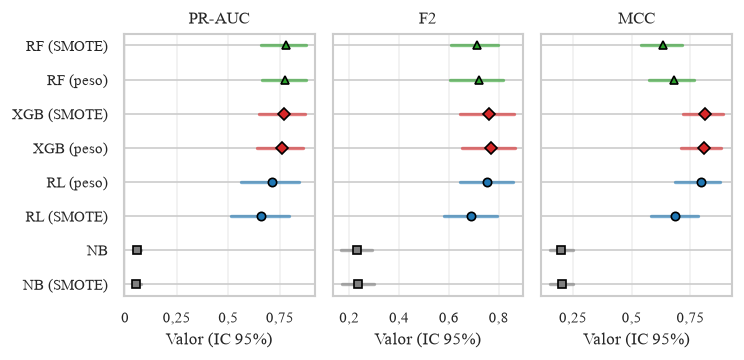

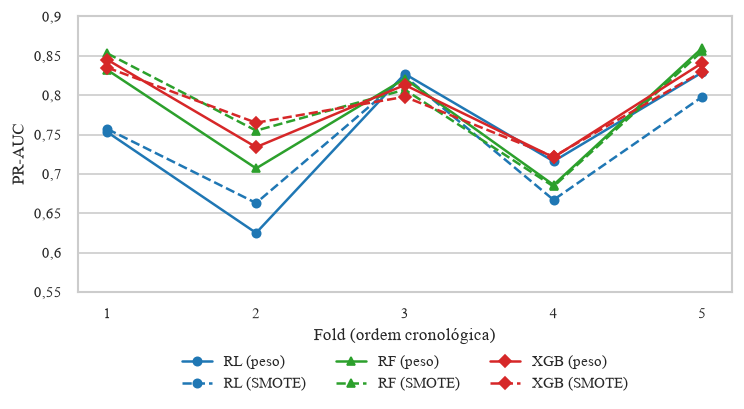

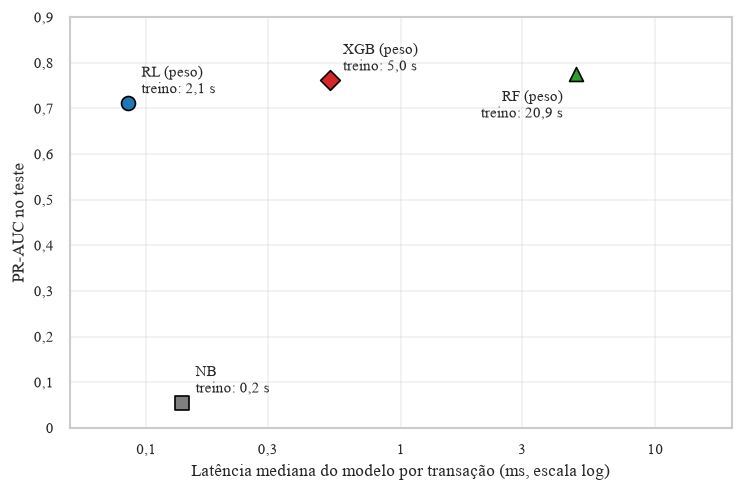

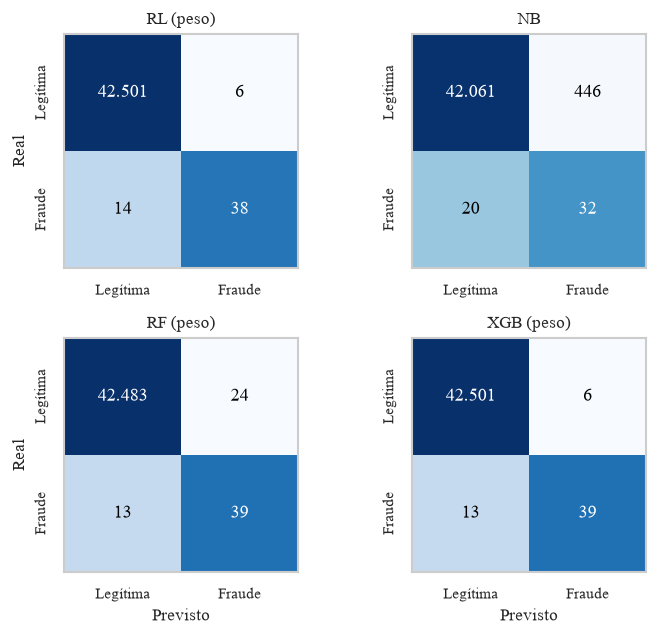

In [8]:
main = pd.read_csv(RESULTS + "resultados_principal.csv")
cv   = pd.read_csv(RESULTS + "resultados_cv_temporal.csv")
inf  = pd.read_csv(RESULTS + "resultados_inferencia.csv")
cv["folds"] = cv["por fold"].apply(ast.literal_eval)
cv["desvio"] = cv["folds"].apply(lambda f: np.std(f, ddof=1))
cv.drop(columns="folds").to_csv(RESULTS + "resultados_cv_temporal.csv", index=False)

# Figura 2: métricas no teste, com IC 95% (bootstrap)
d = main.sort_values("PR-AUC").reset_index(drop=True)
fig, axs = plt.subplots(1, 3, figsize=(LARG, 3.1), sharey=True)
for ax, m in zip(axs, ["PR-AUC", "F2", "MCC"]):
    for i, row in d.iterrows():
        lo, hi = [float(x) for x in re.findall(r"-?\d+\.\d+", row[f"{m} IC"])]
        ax.plot([lo, hi], [i, i], color=cor(row["config"]), lw=2, alpha=0.6)
        ax.plot(row[m], i, marker=marc(row["config"]), color=cor(row["config"]), mec="black", ms=5)
    ax.set_title(m, fontsize=10); ax.set_xlabel("Valor (IC 95%)")
    ax.xaxis.set_major_locator(MaxNLocator(4)); ptbr(ax, y=False); ax.grid(True, axis="x", alpha=.3)
axs[0].set_yticks(range(len(d))); axs[0].set_yticklabels([NOMES[c] for c in d["config"]])
fig.tight_layout(); salvar(fig, "fig_metricas_ic.png")

# Figura 4: PR-AUC por fold (CV temporal), sem o NB
fig, ax = plt.subplots(figsize=(LARG, 3.6))
for _, r in cv[~cv["config"].str.startswith("NB")].iterrows():
    ax.plot(range(1, 6), r["folds"], marker=marc(r["config"]), color=cor(r["config"]),
            ls="--" if "smote" in r["config"] else "-", label=NOMES[r["config"]], ms=5)
ax.set_xticks(range(1, 6)); ax.set_xlabel("Fold (ordem cronológica)"); ax.set_ylabel("PR-AUC")
ax.set_ylim(0.55, 0.9); ax.grid(False, axis="x"); ptbr(ax, x=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
fig.tight_layout(); salvar(fig, "fig_cv_temporal.png")

# Figura 5: qualidade de detecção x latência do modelo
m2 = main.merge(inf, on="config")
fig, ax = plt.subplots(figsize=(LARG, 4.2))
for _, r in m2.iterrows():
    x, y = r["modelo: mediana (ms)"], r["PR-AUC"]
    ax.scatter(x, y, s=70, marker=marc(r["config"]), color=cor(r["config"]), edgecolor="black", zorder=3)
    rot = f"{NOMES[r['config']]}\ntreino: {num(r['treino (s)'], 1)} s"
    if x > 3: ax.annotate(rot, (x, y), textcoords="offset points", xytext=(-8, -26), ha="right", fontsize=9)
    else:     ax.annotate(rot, (x, y), textcoords="offset points", xytext=(8, 6), fontsize=9)
ax.set_xscale("log"); ax.set_xlim(0.05, 20); ax.set_ylim(0, 0.9)
ax.set_xticks([0.1, 0.3, 1, 3, 10]); ptbr(ax)
ax.xaxis.set_minor_formatter(NullFormatter()); ax.grid(True, alpha=.3)
ax.set_xlabel("Latência mediana do modelo por transação (ms, escala log)"); ax.set_ylabel("PR-AUC no teste")
fig.tight_layout(); salvar(fig, "fig_custo_beneficio.png")

# Apêndice: matrizes de confusão no teste
fig, axs = plt.subplots(2, 2, figsize=(LARG, 5.4))
for ax, cfg in zip(axs.ravel(), ["LR+peso", "NB+none", "RF+peso", "XGB+peso"]):
    r = main[main["config"] == cfg].iloc[0]
    cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, num(int(v)), ha="center", va="center", fontsize=11,
                color="white" if v / cm[i].sum() > 0.5 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Legítima", "Fraude"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Legítima", "Fraude"], rotation=90, va="center")
    ax.set_title(NOMES[cfg], fontsize=10)
for ax in axs[1]: ax.set_xlabel("Previsto")
for ax in axs[:, 0]: ax.set_ylabel("Real")
fig.tight_layout(); salvar(fig, "fig_matrizes_confusao.png")

## 9. Reajuste de 4 modelos para as curvas PR e o F2 × limiar

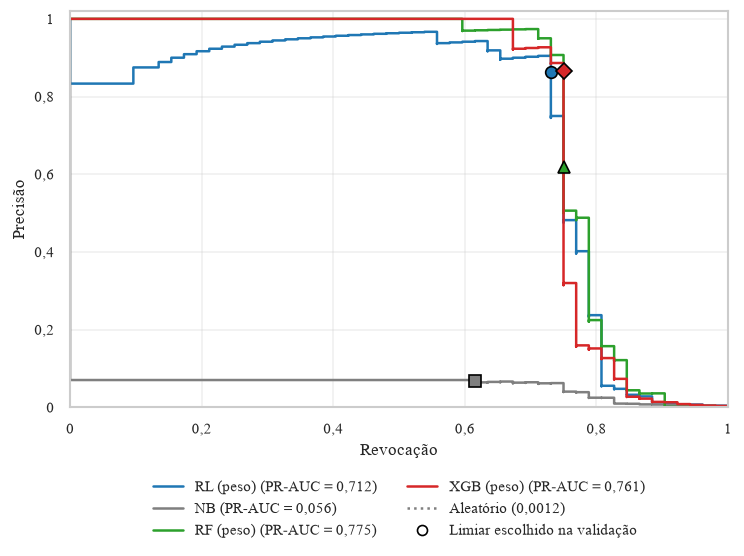

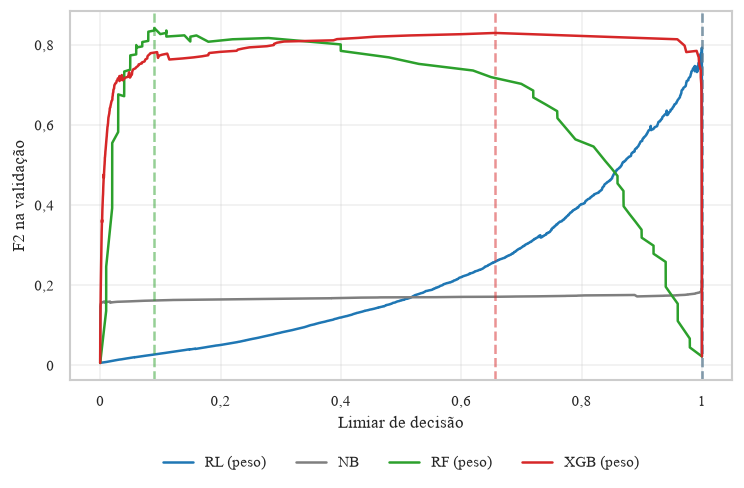

In [9]:
CFG_FIG = [("LR", "peso"), ("NB", "none"), ("RF", "peso"), ("XGB", "peso")]
yva, yte = val_df["Class"].values, test_df["Class"].values
scores = {}
for modelo, bal in CFG_FIG:
    pipe = build_pipe(modelo, bal, FEATURES, train_df["Class"].values)
    pipe.fit(train_df[FEATURES], train_df["Class"].values)
    sv = pipe.predict_proba(val_df[FEATURES])[:, 1]
    st = pipe.predict_proba(test_df[FEATURES])[:, 1]
    scores[f"{modelo}+{bal}"] = (sv, st, melhor_limiar_f2(yva, sv))

# Figura 3: curvas precisão-revocação no teste (círculos = limiar escolhido na validação)
fig, ax = plt.subplots(figsize=(LARG, 4.8))
for cfg, (sv, st, thr) in scores.items():
    p, r, _ = precision_recall_curve(yte, st)
    ax.plot(r, p, drawstyle="steps-post", color=cor(cfg),
            label=f"{NOMES[cfg]} (PR-AUC = {num(average_precision_score(yte, st), 3)})")
    pred = st >= thr
    ax.plot(recall_score(yte, pred), precision_score(yte, pred, zero_division=0),
            marker=marc(cfg), color=cor(cfg), mec="black", ms=7, ls="", zorder=3)
ax.axhline(yte.mean(), ls=":", color="gray", label=f"Aleatório ({num(yte.mean(), 4)})")
h, l = ax.get_legend_handles_labels()
h.append(Line2D([], [], marker="o", ls="", color="white", mec="black")); l.append("Limiar escolhido na validação")
ax.legend(h, l, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
ax.set_xlabel("Revocação"); ax.set_ylabel("Precisão"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.grid(True, alpha=.3); ptbr(ax)
fig.tight_layout(); salvar(fig, "fig_curvas_pr.png")

# Apêndice: F2 em função do limiar (validação)
fig, ax = plt.subplots(figsize=(LARG, 4.2))
for cfg, (sv, st, thr) in scores.items():
    p, r, t = precision_recall_curve(yva, sv)
    f2 = 5 * p[:-1] * r[:-1] / np.clip(4 * p[:-1] + r[:-1], 1e-12, None)
    ax.plot(t, f2, color=cor(cfg), label=NOMES[cfg])
    ax.axvline(thr, color=cor(cfg), ls="--", alpha=0.5)
ax.set_xlabel("Limiar de decisão"); ax.set_ylabel("F2 na validação"); ax.grid(True, alpha=.3); ptbr(ax)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False)
fig.tight_layout(); salvar(fig, "fig_f2_limiar.png")

## 10. Fluxograma do pipeline


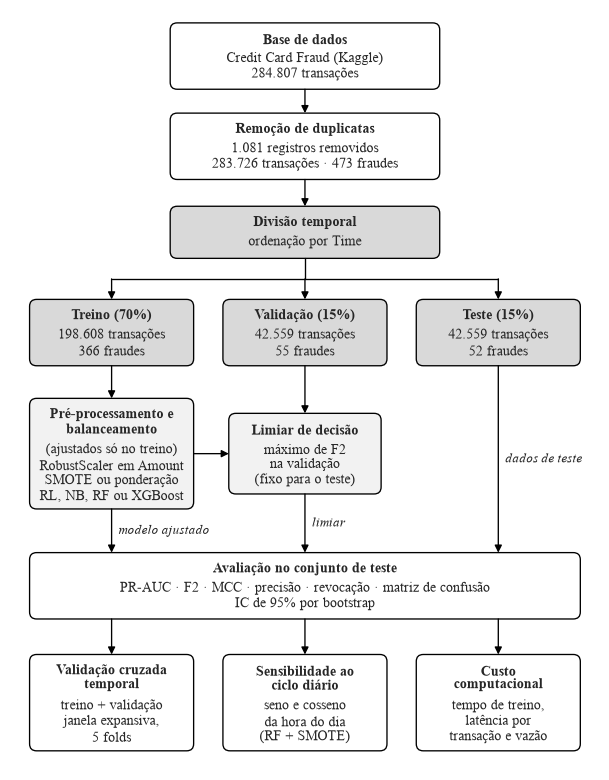

In [10]:
def plot_pipeline(N):
    fig, ax = plt.subplots(figsize=(LARG, LARG * 1.3))
    ax.set_xlim(0, 100); ax.set_ylim(0, 130); ax.axis("off")
    FS = 8.5
    CLARO, MEDIO = "#F2F2F2", "#D9D9D9"
    box = {}

    def caixa(nome, x, w, titulo, corpo, ytopo=None, ycentro=None, fc=CLARO):
        n_t, n_c = titulo.count("\n") + 1, len(corpo)
        h = 3.8 + 2.7 * n_t + 2.45 * n_c
        if ycentro is not None:
            ytopo = ycentro + h / 2
        yc = ytopo - h / 2
        ax.add_patch(FancyBboxPatch((x - w / 2, yc - h / 2), w, h,
                                    boxstyle="round,pad=0,rounding_size=1.2",
                                    fc=fc, ec="black", lw=0.8))
        ax.text(x, ytopo - 1.6, titulo, ha="center", va="top", fontsize=FS,
                fontweight="bold", linespacing=1.1)
        ax.text(x, ytopo - 1.6 - 2.7 * n_t - 0.5, "\n".join(corpo), ha="center",
                va="top", fontsize=FS, linespacing=1.2)
        box[nome] = (x, yc, w, h)

    def topo(n, dx=0):
        x, yc, w, h = box[n]; return (x + dx, yc + h / 2)

    def base(n, dx=0):
        x, yc, w, h = box[n]; return (x + dx, yc - h / 2)

    def seta(p, q, rotulo=None):
        ax.annotate("", xy=q, xytext=p,
                    arrowprops=dict(arrowstyle="-|>", lw=0.8, color="black",
                                    shrinkA=0, shrinkB=0, mutation_scale=9))
        if rotulo:
            ax.text(p[0] + 1.2, (p[1] + q[1]) / 2, rotulo, fontsize=8,
                    style="italic", ha="left", va="center")

    X1, X2, X3 = 17, 50, 83
    caixa("base", X2, 46, "Base de dados",
          ["Credit Card Fraud (Kaggle)", f"{num(N['orig'])} transações"], ytopo=128, fc="white")
    caixa("dup", X2, 46, "Remoção de duplicatas",
          [f"{num(N['dup'])} registros removidos",
           f"{num(N['total'])} transações · {num(N['fraudes'])} fraudes"], ytopo=112.5, fc="white")
    caixa("split", X2, 46, "Divisão temporal", ["ordenação por Time"], ytopo=96.5, fc=MEDIO)
    caixa("tr", X1, 28, "Treino (70%)",
          [f"{num(N['tr'][0])} transações", f"{num(N['tr'][1])} fraudes"], ytopo=80.5, fc=MEDIO)
    caixa("va", X2, 28, "Validação (15%)",
          [f"{num(N['va'][0])} transações", f"{num(N['va'][1])} fraudes"], ytopo=80.5, fc=MEDIO)
    caixa("te", X3, 28, "Teste (15%)",
          [f"{num(N['te'][0])} transações", f"{num(N['te'][1])} fraudes"], ytopo=80.5, fc=MEDIO)
    caixa("pipe", X1, 28, "Pré-processamento e\nbalanceamento",
          ["(ajustados só no treino)", "RobustScaler em Amount",
           "SMOTE ou ponderação", "RL, NB, RF ou XGBoost"], ytopo=63.5)
    yc_pipe = box["pipe"][1]
    caixa("lim", X2, 26, "Limiar de decisão",
          ["máximo de F2", "na validação", "(fixo para o teste)"], ycentro=yc_pipe)
    caixa("aval", X2, 94, "Avaliação no conjunto de teste",
          ["PR-AUC · F2 · MCC · precisão · revocação · matriz de confusão",
           "IC de 95% por bootstrap"], ytopo=37, fc="white")
    caixa("cv", X1, 28, "Validação cruzada\ntemporal",
          ["treino + validação", "janela expansiva,", "5 folds"], ytopo=19.5, fc="white")
    caixa("sens", X2, 28, "Sensibilidade ao\nciclo diário",
          ["seno e cosseno", "da hora do dia", "(RF + SMOTE)"], ytopo=19.5, fc="white")
    caixa("custo", X3, 28, "Custo\ncomputacional",
          ["tempo de treino,", "latência por", "transação e vazão"], ytopo=19.5, fc="white")

    seta(base("base"), topo("dup")); seta(base("dup"), topo("split"))
    yb = base("split")[1]; ybar = (yb + topo("tr")[1]) / 2
    ax.plot([X2, X2], [yb, ybar], color="black", lw=0.8)
    ax.plot([X1, X3], [ybar, ybar], color="black", lw=0.8)
    for x, n in ((X1, "tr"), (X2, "va"), (X3, "te")):
        seta((x, ybar), topo(n))
    seta(base("tr"), topo("pipe"))
    seta((X1 + 14, yc_pipe), (X2 - 13, yc_pipe))
    seta(base("va"), topo("lim"))
    seta(base("pipe"), topo("aval", X1 - X2), "modelo ajustado")
    seta(base("lim"), topo("aval"), "limiar")
    seta(base("te"), topo("aval", X3 - X2), "dados de teste")
    for n, x in (("cv", X1), ("sens", X2), ("custo", X3)):
        seta(base("aval", x - X2), topo(n))
    salvar(fig, "fig_pipeline.png")

n_orig = len(pd.read_csv(CSV_PATH))
N = {"orig": n_orig, "dup": n_orig - len(df), "total": len(df),
     "fraudes": int(df["Class"].sum()),
     "tr": (len(train_df), int(train_df["Class"].sum())),
     "va": (len(val_df), int(val_df["Class"].sum())),
     "te": (len(test_df), int(test_df["Class"].sum()))}
plot_pipeline(N)